# Respira — Original EfficientNetB0: full retraining and evaluation

## 1. Imports and experiment configuration

In [11]:
from pathlib import Path
import os, re, json, hashlib, random, sys, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
    recall_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, log_loss)
from sklearn.preprocessing import label_binarize

ROOT = Path.cwd()
DATASET = ROOT / "data" / "chest_xray"
OUT = ROOT / "outputs" / "original_efficientnet_retraining"
MODEL_DIR = ROOT / "models" / "original_efficientnet_retraining"
SPLIT_DIR = OUT / "splits"
for directory in (OUT, MODEL_DIR, SPLIT_DIR): directory.mkdir(parents=True, exist_ok=True)
BEST_MODEL = MODEL_DIR / "best_model.keras"
FINAL_MODEL = MODEL_DIR / "final_model.keras"
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
MAX_EPOCHS = 15
VAL_SIZE = 0.15
CLASS_NAMES = ["Normal", "Bacterial", "Viral"]
LABEL_TO_ID = {v:i for i,v in enumerate(CLASS_NAMES)}
# True: reuse your old train/val/test CSVs, if they exist, to match the original split exactly.
# False: regenerate the original GroupShuffleSplit(seed=42, test_size=0.15) from raw folders.
USE_EXISTING_SPLITS = True

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
print("TensorFlow:", tf.__version__, "Python:", sys.version.split()[0])
print("Working directory:", ROOT)
assert DATASET.is_dir(), f"Missing dataset: {DATASET}"
print("Outputs:", OUT)


TensorFlow: 2.21.0 Python: 3.12.6
Working directory: /Users/sivani/Desktop/xray_model
Outputs: /Users/sivani/Desktop/xray_model/outputs/original_efficientnet_retraining


## 2. data splits

In [12]:
VALID_EXT = {".jpg", ".jpeg", ".png"}
def label_from_path(p):
    if p.parent.name.upper() == "NORMAL": return "Normal"
    name = p.name.lower()
    if "bacteria" in name: return "Bacterial"
    if "virus" in name: return "Viral"
    return None

def original_patient_id(p):
    m = re.search(r"(person\\d+)", p.stem.lower())
    return m.group(1) if m else p.stem

def discover(folder):
    records = []
    for category in ("NORMAL", "PNEUMONIA"):
        d = DATASET / folder / category
        assert d.is_dir(), f"Missing {d}"
        for p in sorted(d.iterdir()):
            if p.suffix.lower() not in VALID_EXT: continue
            label = label_from_path(p)
            if label is not None:
                records.append({"filepath":str(p.resolve()), "label":label,
                                "patient_id":original_patient_id(p)})
    return pd.DataFrame(records)

old = ROOT / "data" / "splits"
required = [old / f"{name}.csv" for name in ("train", "val", "test")]
if USE_EXISTING_SPLITS and all(f.exists() for f in required):
    train_df, val_df, test_df = [pd.read_csv(f) for f in required]
    print("Using ORIGINAL saved split CSVs.")
else:
    full_train = discover("train")
    test_df = discover("test")
    gss = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE, random_state=SEED)
    a,b = next(gss.split(full_train, groups=full_train.patient_id))
    train_df = full_train.iloc[a].reset_index(drop=True)
    val_df = full_train.iloc[b].reset_index(drop=True)
    print("Regenerated original-style split from data/chest_xray folders.")

parts = {"train":train_df.copy(), "val":val_df.copy(), "test":test_df.copy()}
for name, df in parts.items():
    assert {"filepath","label"}.issubset(df.columns), f"{name}: missing required columns"
    df["filepath"] = df["filepath"].map(lambda s: str((ROOT / str(s)).resolve()) if not Path(str(s)).is_absolute() else str(Path(str(s)).resolve()))
    df["patient_id"] = df["filepath"].map(lambda s: original_patient_id(Path(s)))
    df["label_id"] = df.label.map(LABEL_TO_ID)
    assert df.label_id.notna().all(), f"Unknown class in {name}"
    assert df.filepath.map(lambda s: Path(s).is_file()).all(), f"Missing images in {name}"
    df["label_id"] = df.label_id.astype(int)
    df.to_csv(SPLIT_DIR / f"{name}.csv", index=False)
    print(f"\n{name.upper()} ({len(df)} images)")
    print(df.label.value_counts().reindex(CLASS_NAMES,fill_value=0).to_string())

print("\nExpected ORIGINAL test size: 624. Actual:",len(parts["test"]))
if len(parts["test"]) != 624:
    print("WARNING: Test partition is different from the original 624-image evaluation.")


Using ORIGINAL saved split CSVs.

TRAIN (4541 images)
label
Normal       1130
Bacterial    2232
Viral        1179

VAL (691 images)
label
Normal       219
Bacterial    306
Viral        166

TEST (624 images)
label
Normal       234
Bacterial    242
Viral        148

Expected ORIGINAL test size: 624. Actual: 624


## 3. Split-integrity and exact-duplicate audit



In [ ]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path,"rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""): h.update(block)
    return h.hexdigest()

for name,df in parts.items():
    df["sha256"] = df.filepath.map(sha256_file)
    df.to_csv(SPLIT_DIR / f"{name}.csv",index=False)

audit=[]
for left,right in (("train","val"),("train","test"),("val","test")):
    a,b = parts[left],parts[right]
    group_overlap = set(a.patient_id) & set(b.patient_id)
    hash_overlap = set(a.sha256) & set(b.sha256)
    audit.append({"pair":f"{left} vs {right}", "shared_filename_ids":len(group_overlap),
                  "shared_exact_image_hashes":len(hash_overlap)})
audit_df = pd.DataFrame(audit)
display(audit_df)
audit_df.to_csv(OUT/"split_integrity_audit.csv",index=False)
if audit_df.shared_filename_ids.sum() or audit_df.shared_exact_image_hashes.sum():
    print("CAUTION: The original split has potential independence/leakage concerns.")
    print("Filename ID collisions do not, by themselves, prove the same actual patient.")
print("The notebook continues for historical reproducibility, not a patient-independent claim.")


,pair,shared_filename_ids,shared_exact_image_hashes
0,train vs val,0,1
1,train vs test,0,0
2,val vs test,0,0


CAUTION: The original split has potential independence/leakage concerns.
Filename ID collisions do not, by themselves, prove the same actual patient.
The notebook continues for historical reproducibility, not a patient-independent claim.


## 4. TensorFlow datasets (original preprocessing: 224×224 float pixels, no extra normalization)

Keras EfficientNetB0 includes its own rescaling behavior; do not apply `preprocess_input`/divide by 255 again for this architecture.

In [14]:
def load_image(filepath,label):
    image=tf.io.read_file(filepath)
    image=tf.io.decode_jpeg(image,channels=3)
    image=tf.image.resize(image,IMG_SIZE)
    image=tf.cast(image,tf.float32)
    return image,label

def make_dataset(df,shuffle=False):
    ds=tf.data.Dataset.from_tensor_slices((df.filepath.to_numpy(dtype=str),
                                           df.label_id.to_numpy(dtype=np.int32)))
    if shuffle: ds=ds.shuffle(len(df),seed=SEED)
    return ds.map(load_image,num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds=make_dataset(parts["train"],shuffle=True)
val_ds=make_dataset(parts["val"])
test_ds=make_dataset(parts["test"])
print("Train batches:",len(train_ds),"Validation:",len(val_ds),"Test:",len(test_ds))


Train batches: 142 Validation: 22 Test: 20


## 5. Class weights and original EfficientNetB0 architecture

In [15]:
y_train=parts["train"].label_id.to_numpy()
assert set(y_train)=={0,1,2}, "Training split must contain all three classes."
weights=compute_class_weight(class_weight="balanced",classes=np.arange(3),y=y_train)
class_weights={i:float(w) for i,w in enumerate(weights)}
print("Class weights:",dict(zip(CLASS_NAMES,weights.round(4))))

augmentation=tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08),
    layers.RandomTranslation(height_factor=0.05,width_factor=0.05),
    layers.RandomContrast(0.10),
],name="augmentation")
base_model=tf.keras.applications.EfficientNetB0(
    include_top=False,weights="imagenet",input_shape=(224,224,3))
base_model.trainable=False
inputs=layers.Input(shape=(224,224,3))
x=augmentation(inputs)
x=base_model(x,training=False)
x=layers.GlobalAveragePooling2D()(x)
x=layers.Dropout(0.35)(x)
x=layers.Dense(128,activation="relu")(x)
x=layers.Dropout(0.25)(x)
outputs=layers.Dense(3,activation="softmax")(x)
model=models.Model(inputs,outputs,name="respira_original_efficientnetb0")
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss="sparse_categorical_crossentropy",metrics=["accuracy"])
model.summary()


Class weights: {'Normal': np.float64(1.3395), 'Bacterial': np.float64(0.6782), 'Viral': np.float64(1.2839)}


Model: "respira_original_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,926 (16.07 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 6. Train 


In [16]:
callbacks=[
    tf.keras.callbacks.ModelCheckpoint(str(BEST_MODEL),monitor="val_loss",save_best_only=True,verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=4,restore_best_weights=True,verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.3,patience=2,min_lr=1e-6,verbose=1),
    tf.keras.callbacks.CSVLogger(str(OUT/"training_history.csv"))
]
history=model.fit(train_ds,validation_data=val_ds,epochs=MAX_EPOCHS,
                  class_weight=class_weights,callbacks=callbacks)
model.save(FINAL_MODEL)
print("Best model:",BEST_MODEL)
print("Final restored-weight model:",FINAL_MODEL)


Epoch 1/15


/Users/sivani/Desktop/xray_model/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


142/142 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.6644 - loss: 0.7089
Epoch 1: val_loss improved from None to 0.61223, saving model to /Users/sivani/Desktop/xray_model/models/original_efficientnet_retraining/best_model.keras

Epoch 1: finished saving model to /Users/sivani/Desktop/xray_model/models/original_efficientnet_retraining/best_model.keras
142/142 ━━━━━━━━━━━━━━━━━━━━ 83s 545ms/step - accuracy: 0.6644 - loss: 0.7089 - val_accuracy: 0.7236 - val_loss: 0.6122 - learning_rate: 0.0010
Epoch 2/15
142/142 ━━━━━━━━━━━━━━━━━━━━ 0s 501ms/step - accuracy: 0.7181 - loss: 0.6019
Epoch 2: val_loss did not improve from 0.61223
142/142 ━━━━━━━━━━━━━━━━━━━━ 81s 571ms/step - accuracy: 0.7181 - loss: 0.6019 - val_accuracy: 0.6990 - val_loss: 0.6129 - learning_rate: 0.0010
Epoch 3/15
142/142 ━━━━━━━━━━━━━━━━━━━━ 0s 514ms/step - accuracy: 0.7318 - loss: 0.5678
Epoch 3: val_loss improved from 0.61223 to 0.57490, saving model to /Users/sivani/Desktop/xray_model/models/original_efficientnet_re

## 7. Learning curves

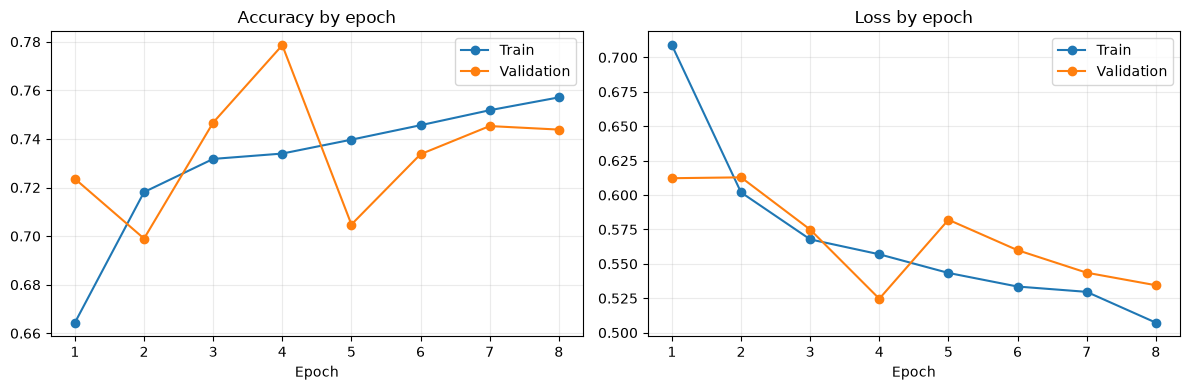

In [17]:
hist=pd.read_csv(OUT/"training_history.csv")
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,a,b,title in zip(axes,["accuracy","loss"],["val_accuracy","val_loss"],
                        ["Accuracy by epoch","Loss by epoch"]):
    ax.plot(hist.epoch+1,hist[a],marker="o",label="Train")
    ax.plot(hist.epoch+1,hist[b],marker="o",label="Validation")
    ax.set(xlabel="Epoch",title=title);ax.legend();ax.grid(alpha=0.25)
plt.tight_layout();plt.savefig(OUT/"training_curves.png",dpi=180);plt.show()


## 8. Evaluate the best checkpoint on the ORIGINAL test partition

In [18]:
best=tf.keras.models.load_model(BEST_MODEL)
test_loss,keras_accuracy=best.evaluate(test_ds,verbose=1)
probabilities=best.predict(test_ds,verbose=1)
y_true=parts["test"].label_id.to_numpy()
y_pred=np.argmax(probabilities,axis=1)
cm=confusion_matrix(y_true,y_pred,labels=[0,1,2])
print("\nCLASSIFICATION REPORT")
print(classification_report(y_true,y_pred,labels=[0,1,2],target_names=CLASS_NAMES,digits=4,zero_division=0))
print("CONFUSION MATRIX (rows actual; columns predicted):\n",cm)


20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 408ms/step - accuracy: 0.8365 - loss: 0.5776
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 447ms/step

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9167    0.7991    0.8539       234
   Bacterial     0.8894    0.8636    0.8763       242
       Viral     0.6811    0.8514    0.7568       148

    accuracy                         0.8365       624
   macro avg     0.8290    0.8380    0.8290       624
weighted avg     0.8502    0.8365    0.8395       624

CONFUSION MATRIX (rows actual; columns predicted):
 [[187  10  37]
 [ 11 209  22]
 [  6  16 126]]


## 9. Complete metric tables, including specificity and binary pneumonia screening

In [19]:
summary={
    "test_images":int(len(y_true)),
    "test_loss":float(test_loss),
    "accuracy":float(accuracy_score(y_true,y_pred)),
    "balanced_accuracy":float(balanced_accuracy_score(y_true,y_pred)),
    "macro_precision":float(precision_score(y_true,y_pred,average="macro",zero_division=0)),
    "macro_recall":float(recall_score(y_true,y_pred,average="macro",zero_division=0)),
    "macro_f1":float(f1_score(y_true,y_pred,average="macro",zero_division=0)),
    "weighted_f1":float(f1_score(y_true,y_pred,average="weighted",zero_division=0)),
    "log_loss":float(log_loss(y_true,probabilities,labels=[0,1,2])),
}
class_metrics=[]
for i,name in enumerate(CLASS_NAMES):
    tp=int(cm[i,i]);fn=int(cm[i,:].sum()-tp);fp=int(cm[:,i].sum()-tp);tn=int(cm.sum()-tp-fn-fp)
    class_metrics.append({
        "class":name,"support":int(cm[i,:].sum()),"TP":tp,"FP":fp,"FN":fn,"TN":tn,
        "precision":tp/(tp+fp) if tp+fp else np.nan,
        "recall_sensitivity":tp/(tp+fn) if tp+fn else np.nan,
        "specificity":tn/(tn+fp) if tn+fp else np.nan,
        "f1":2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan})
per_class=pd.DataFrame(class_metrics)
true_pneumonia=(y_true!=0).astype(int)
pred_pneumonia=(y_pred!=0).astype(int)
screen_cm=confusion_matrix(true_pneumonia,pred_pneumonia,labels=[0,1])
tn,fp,fn,tp=screen_cm.ravel()
summary.update({
    "binary_pneumonia_sensitivity":float(tp/(tp+fn)) if tp+fn else None,
    "binary_pneumonia_specificity":float(tn/(tn+fp)) if tn+fp else None,
    "binary_pneumonia_accuracy":float((tp+tn)/screen_cm.sum()),
})
display(pd.DataFrame([summary]).T.rename(columns={0:"value"}))
display(per_class)
pd.DataFrame([summary]).to_csv(OUT/"overall_metrics.csv",index=False)
per_class.to_csv(OUT/"per_class_metrics.csv",index=False)
pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(OUT/"confusion_matrix.csv")
pd.DataFrame(screen_cm,index=["Actual Normal","Actual Pneumonia"],
             columns=["Pred Normal","Pred Pneumonia"]).to_csv(OUT/"binary_screening_confusion_matrix.csv")
(OUT/"metrics.json").write_text(json.dumps(summary,indent=2))


,value
test_images,624.000000
test_loss,0.577586
accuracy,0.836538
balanced_accuracy,0.838044
macro_precision,0.829036
macro_recall,0.838044
macro_f1,0.828983
weighted_f1,0.839544
log_loss,0.577586
binary_pneumonia_sensitivity,0.956410


,class,support,TP,FP,FN,TN,precision,recall_sensitivity,specificity,f1
0,Normal,234,187,17,47,373,0.916667,0.799145,0.956410,0.853881
1,Bacterial,242,209,26,33,356,0.889362,0.863636,0.931937,0.876310
2,Viral,148,126,59,22,417,0.681081,0.851351,0.876050,0.756757


477

## 10. Confusion matrix figures

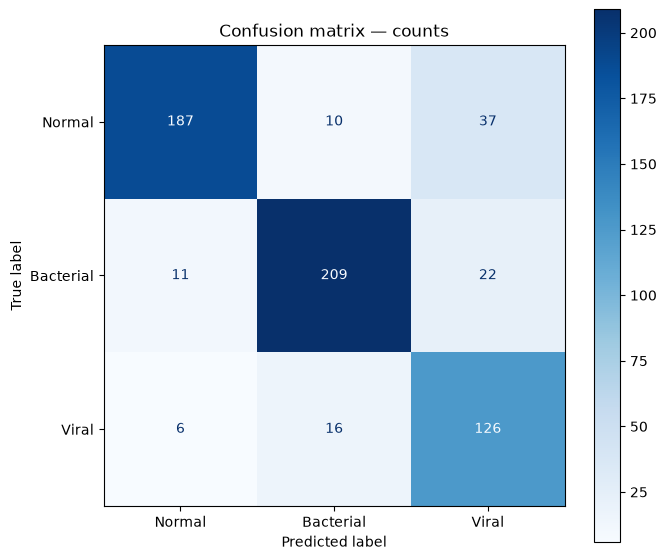

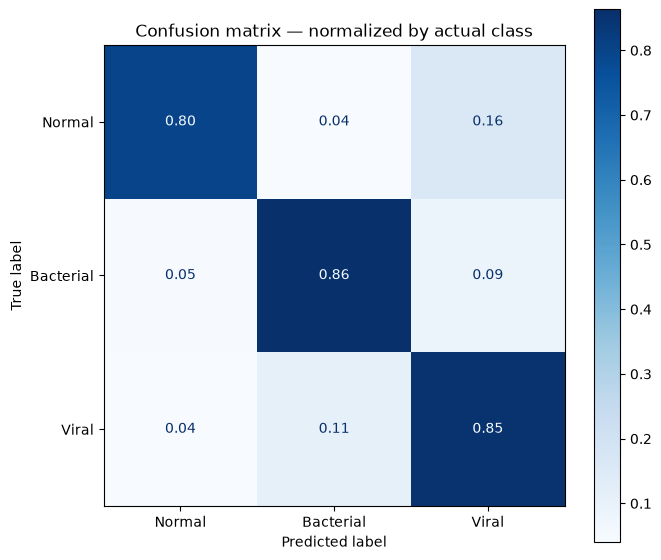

In [20]:
for normalize,filename,title in [
    (None,"confusion_matrix_counts.png","Confusion matrix — counts"),
    ("true","confusion_matrix_normalized.png","Confusion matrix — normalized by actual class")]:
    fig,ax=plt.subplots(figsize=(7,6))
    ConfusionMatrixDisplay.from_predictions(y_true,y_pred,labels=[0,1,2],
        display_labels=CLASS_NAMES,normalize=normalize,cmap="Blues",
        values_format="d" if normalize is None else ".2f",ax=ax)
    ax.set_title(title)
    plt.tight_layout();plt.savefig(OUT/filename,dpi=180);plt.show()


## 11. ROC-AUC and precision–recall curves (one-vs-rest)

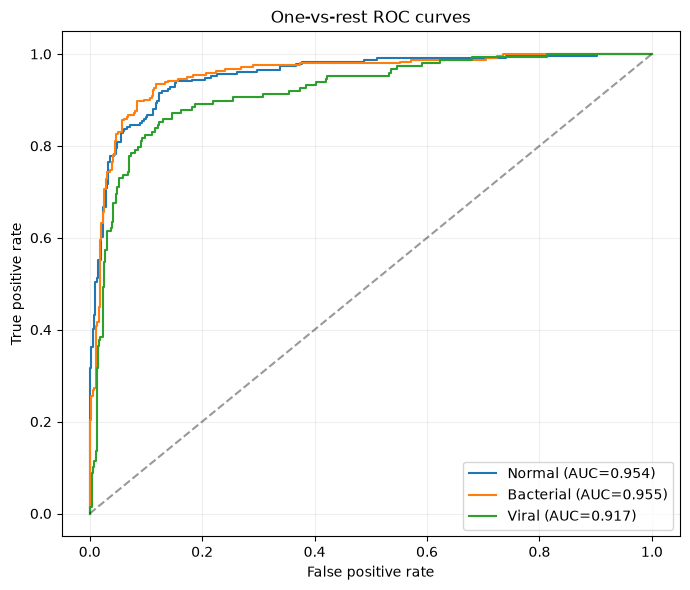

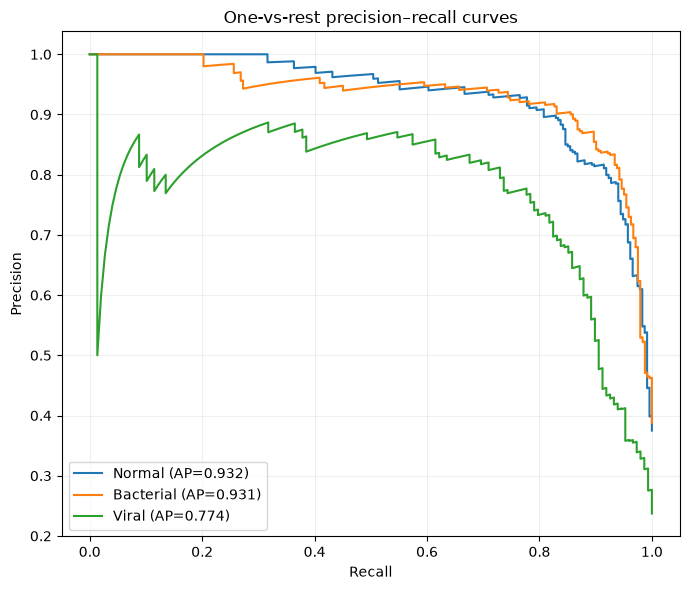

,class,roc_auc,average_precision
0,Normal,0.953638,0.932455
1,Bacterial,0.955281,0.931439
2,Viral,0.917499,0.774202


In [21]:
onehot=np.eye(3,dtype=int)[y_true]
roc_rows=[]
fig_roc,ax_roc=plt.subplots(figsize=(7,6))
fig_pr,ax_pr=plt.subplots(figsize=(7,6))
for i,name in enumerate(CLASS_NAMES):
    if len(np.unique(onehot[:,i]))<2: continue
    fpr,tpr,_=roc_curve(onehot[:,i],probabilities[:,i])
    precision,recall,_=precision_recall_curve(onehot[:,i],probabilities[:,i])
    auc=roc_auc_score(onehot[:,i],probabilities[:,i])
    ap=average_precision_score(onehot[:,i],probabilities[:,i])
    roc_rows.append({"class":name,"roc_auc":float(auc),"average_precision":float(ap)})
    ax_roc.plot(fpr,tpr,label=f"{name} (AUC={auc:.3f})")
    ax_pr.plot(recall,precision,label=f"{name} (AP={ap:.3f})")
ax_roc.plot([0,1],[0,1],"k--",alpha=0.4)
ax_roc.set(xlabel="False positive rate",ylabel="True positive rate",title="One-vs-rest ROC curves")
ax_pr.set(xlabel="Recall",ylabel="Precision",title="One-vs-rest precision–recall curves")
for ax in (ax_roc,ax_pr):ax.legend();ax.grid(alpha=0.2)
fig_roc.tight_layout();fig_roc.savefig(OUT/"roc_curves.png",dpi=180)
fig_pr.tight_layout();fig_pr.savefig(OUT/"precision_recall_curves.png",dpi=180)
plt.show()
roc_df=pd.DataFrame(roc_rows);display(roc_df);roc_df.to_csv(OUT/"auc_and_ap.csv",index=False)
summary["macro_roc_auc_ovr"]=float(roc_df.roc_auc.mean())


## 12. Calibration metrics and reliability diagram 

ECE (15 bins): 0.1225 | Multiclass Brier: 0.3017


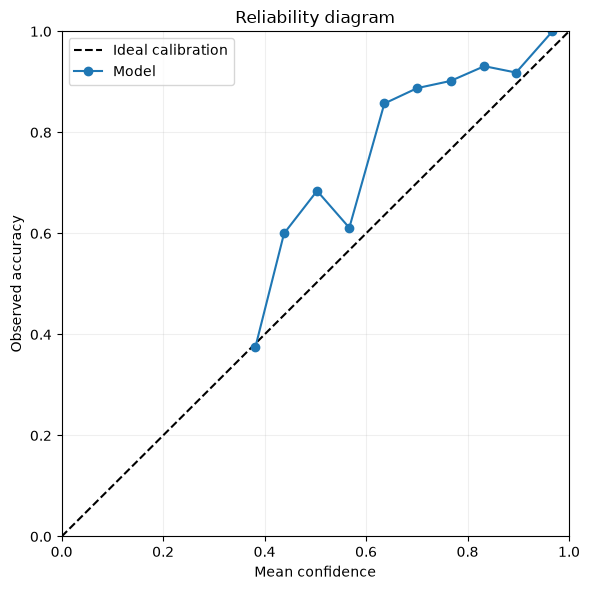

607

In [22]:
def expected_calibration_error(y,p,n_bins=15):
    confidence=p.max(axis=1)
    correct=(p.argmax(axis=1)==y).astype(float)
    edges=np.linspace(0,1,n_bins+1)
    ece=0.0
    rows=[]
    for k in range(n_bins):
        mask=(confidence>=edges[k]) & ((confidence<edges[k+1]) if k<n_bins-1 else (confidence<=edges[k+1]))
        if mask.any():
            acc=float(correct[mask].mean()); conf=float(confidence[mask].mean())
            ece+=float(mask.mean())*abs(acc-conf)
            rows.append({"bin":k,"count":int(mask.sum()),"mean_confidence":conf,"accuracy":acc})
    return float(ece),pd.DataFrame(rows)

ece,calibration=expected_calibration_error(y_true,probabilities)
brier=float(np.mean(np.sum((probabilities-onehot)**2,axis=1)))
summary["ece_15_bins"]=ece
summary["multiclass_brier_score"]=brier
print(f"ECE (15 bins): {ece:.4f} | Multiclass Brier: {brier:.4f}")
calibration.to_csv(OUT/"calibration_bins.csv",index=False)
fig,ax=plt.subplots(figsize=(6,6))
ax.plot([0,1],[0,1],"k--",label="Ideal calibration")
ax.plot(calibration.mean_confidence,calibration.accuracy,"o-",label="Model")
ax.set(xlabel="Mean confidence",ylabel="Observed accuracy",title="Reliability diagram",xlim=(0,1),ylim=(0,1))
ax.legend();ax.grid(alpha=0.2)
plt.tight_layout();plt.savefig(OUT/"reliability_diagram.png",dpi=180);plt.show()
pd.DataFrame([summary]).to_csv(OUT/"overall_metrics.csv",index=False)
(OUT/"metrics.json").write_text(json.dumps(summary,indent=2))


## 13. Save per-image predictions and experiment provenance

In [23]:
predictions=parts["test"][["filepath","label","patient_id"]].copy().reset_index(drop=True)
predictions["predicted_label"]=[CLASS_NAMES[i] for i in y_pred]
predictions["correct"]=y_pred==y_true
predictions["confidence"]=probabilities.max(axis=1)
for i,name in enumerate(CLASS_NAMES):
    predictions[f"prob_{name.lower()}"]=probabilities[:,i]
predictions.to_csv(OUT/"test_predictions.csv",index=False)

config={
    "experiment":"original_efficientnetb0_retraining",
    "created_utc":datetime.now(timezone.utc).isoformat(),
    "tensorflow_version":tf.__version__,
    "seed":SEED,"architecture":"EfficientNetB0 ImageNet pretrained, frozen backbone",
    "input_size":IMG_SIZE,"batch_size":BATCH_SIZE,"max_epochs":MAX_EPOCHS,
    "optimizer":"Adam","initial_learning_rate":0.001,
    "loss":"sparse_categorical_crossentropy",
    "augmentation":["rotation 0.03","zoom 0.08","translation 0.05","contrast 0.10"],
    "class_weights":class_weights,
    "split_source":"existing saved CSVs" if USE_EXISTING_SPLITS and all(f.exists() for f in required) else "regenerated original-style split",
    "train_count":len(parts["train"]),"val_count":len(parts["val"]),"test_count":len(parts["test"]),
    "best_model":str(BEST_MODEL),
    "limitations":"Filename-derived IDs are not verified patient IDs; original test split may share filename IDs with train; exact duplicates audited separately. Results are not guaranteed to match prior run."
}
(OUT/"experiment_config.json").write_text(json.dumps(config,indent=2))
print("Best model:",BEST_MODEL)
print("All reports and figures:",OUT)
print("Test accuracy:",f"{summary['accuracy']*100:.2f}%")
print("Balanced accuracy:",f"{summary['balanced_accuracy']*100:.2f}%")
print("Macro-F1:",f"{summary['macro_f1']*100:.2f}%")


Best model: /Users/sivani/Desktop/xray_model/models/original_efficientnet_retraining/best_model.keras
All reports and figures: /Users/sivani/Desktop/xray_model/outputs/original_efficientnet_retraining
Test accuracy: 83.65%
Balanced accuracy: 83.80%
Macro-F1: 82.90%
